<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [6]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), "scripts"))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from triangle_sol import TriangleSolution
from ga import genetic_algorithm
from ga_utils import get_fitness
from experiments import (
    run_grid_search,
    print_grid_search_results,
    plot_grid_search_results,
    plot_fitness_history,
)
from operators import (
    # selection
    roulette_wheel_selection,
    rank_based_selection,
    tournament_selection,
    # crossover
    one_point_crossover,
    two_point_crossover,
    uniform_crossover,
    # mutation
    triangle_gaussian_mutation,
    triangle_color_mutation,
    triangle_vertex_mutation,
    triangle_level_mutation,
)

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

Image size  : 300 x 400 px
Array shape : (400, 300, 4)


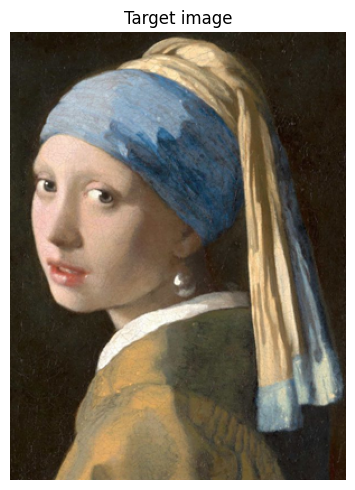

In [8]:
IMG_PATH = "project_info/girl_pearl_earing.png"

target_img = Image.open(IMG_PATH).convert("RGBA")
target_arr = np.array(target_img, dtype=np.int16)

IMG_WIDTH, IMG_HEIGHT = target_img.size   # (width, height) from PIL

print(f"Image size  : {IMG_WIDTH} x {IMG_HEIGHT} px")
print(f"Array shape : {target_arr.shape}")

# Wire the target into TriangleSolution so every instance uses it automatically
TriangleSolution.target_array = target_arr
TriangleSolution.__init__.__defaults__  # sanity-check defaults still present

plt.figure(figsize=(4, 5))
plt.imshow(target_arr)
plt.title("Target image")
plt.axis("off")
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [10]:
sol = TriangleSolution()
sol.representation

array([ 28,  40, 272,  84, 187, 142,  33, 253,  62, 205, 178,  42,  91,
        66, 150, 343,  93,  21,  73,  97, 270, 381,  97,  56, 253,  63,
       196, 232, 119, 240, 142, 397, 224, 100, 182, 352, 122,  17, 165,
       165, 154, 208,  67, 121, 244,  56, 208, 200, 112,  28, 199, 312,
       267, 218, 282, 141, 198, 137,  32, 207, 219, 348,  16, 277, 239,
       378, 148,  56,   3, 146, 214, 381,  49, 364, 109, 178, 106,  12,
       239,  42,  67,  17, 111, 112,  51, 267, 157, 136,  71,  70, 284,
       209, 137, 256, 211, 248, 142, 202, 201, 103, 222, 214, 246,  92,
        99, 372, 169,  67, 213, 137,  62, 242,  99, 381, 185,  47, 180,
        72,  30, 130, 208, 278, 203, 117,  73, 355, 253,  27, 239,  15,
         3, 213,  99, 307,  77,  58, 251, 228,  65, 201, 229,  71, 256,
        69, 205, 295, 202, 179, 103,  73, 164,  67, 264, 370,  12, 341,
        36, 130, 176, 221, 289, 110, 148, 180, 145, 236,  93,  31, 244,
       227, 113, 375, 200, 340, 118,  26, 232,  56, 100,  20, 15

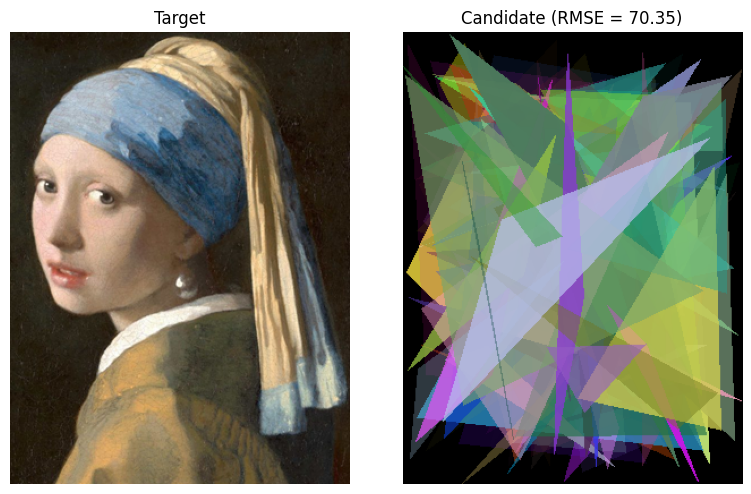

In [11]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Baseline GA Run</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

A single run with sensible defaults to confirm everything works end-to-end.

In [12]:
BASELINE_PARAMS = dict(
    population_size     = 50,
    n_generations       = 200,     # increase for better quality
    selection_method    = "rank",
    crossover_fn        = one_point_crossover,
    mutation_fn         = triangle_level_mutation,
    crossover_rate      = 0.9,
    mutation_rate       = 0.02,
    mutation_rate_decay = 0.0,
    sigma_vertex        = 20,      # pixel-scale (images are ~300x400)
    sigma_colour        = 20,
    elitism_n           = 2,
    n_jobs              = -1,
    verbose             = True,
    verbose_every       = 25,
)

best_sol, history, avg_history = genetic_algorithm(**BASELINE_PARAMS)
print(f"Best RMSE : {get_fitness(best_sol):.4f}")

Gen    0 | best RMSE: 60.6980 | avg RMSE: 68.9596 | mut rate: 0.02000
Gen   25 | best RMSE: 52.4044 | avg RMSE: 52.9624 | mut rate: 0.02000
Gen   50 | best RMSE: 50.1529 | avg RMSE: 51.1348 | mut rate: 0.02000
Gen   75 | best RMSE: 48.7259 | avg RMSE: 49.2151 | mut rate: 0.02000
Gen  100 | best RMSE: 47.0674 | avg RMSE: 47.6124 | mut rate: 0.02000
Gen  125 | best RMSE: 45.9087 | avg RMSE: 46.3759 | mut rate: 0.02000
Gen  150 | best RMSE: 45.1285 | avg RMSE: 45.6502 | mut rate: 0.02000
Gen  175 | best RMSE: 44.2627 | avg RMSE: 44.6635 | mut rate: 0.02000
Gen  199 | best RMSE: 43.8882 | avg RMSE: 44.0811 | mut rate: 0.02000

Finished. Best RMSE: 43.8882
Best RMSE : 43.8882


<h3 id="chapter4.1" style="color:#89AC76;">4.1 Convergence Plot</h3>

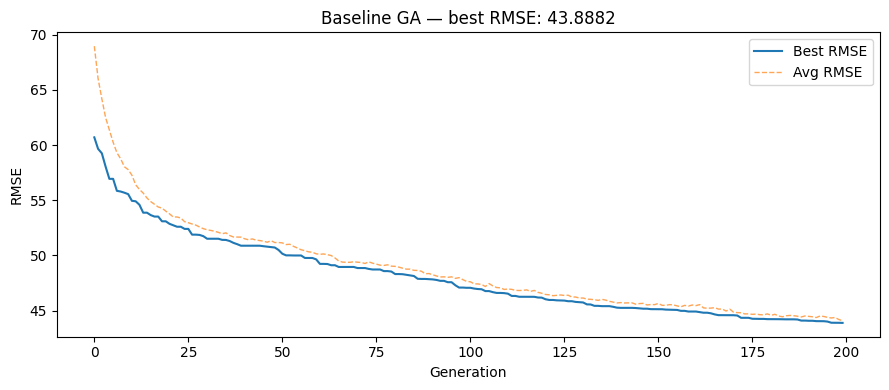

In [13]:
plot_fitness_history(
    history,
    avg_history,
    title=f"Baseline GA — best RMSE: {history[-1]:.4f}",
)

<h2 id="chapter4" style="color:#89AC76;">5. Best Candidate vs. Target </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

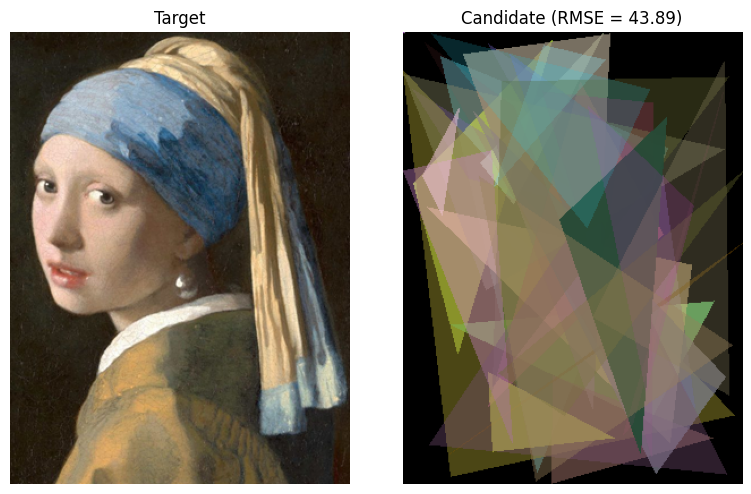

In [14]:
best_sol.show()

<h2 id="chapter4" style="color:#89AC76;">6. Custom Run - Swap Operators </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

Try two-point crossover + tournament selection to compare.

In [ ]:
best_custom, hist_custom, avg_hist_custom = genetic_algorithm(
    population_size     = 800,
    n_generations       = 1000,
    selection_method    = tournament_selection,
    crossover_fn        = two_point_crossover,
    mutation_fn         = triangle_level_mutation,
    crossover_rate      = 0.9,
    mutation_rate       = 0.02,
    sigma_vertex        = 20,
    sigma_colour        = 20,
    elitism_n           = 2,
    n_jobs              = -1,
    verbose             = True,
    verbose_every       = 25,
)

# Compare both runs
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history,      label=f"Baseline (rank + 1pt XO)  RMSE={history[-1]:.4f}")
ax.plot(hist_custom,  label=f"Custom  (tourn + 2pt XO)  RMSE={hist_custom[-1]:.4f}")
ax.set_xlabel("Generation")
ax.set_ylabel("Best RMSE")
ax.set_title("Operator Comparison")
ax.legend()
plt.tight_layout()
plt.show()

Gen    0 | best RMSE: 58.3976 | avg RMSE: 68.7113 | mut rate: 0.02000
Gen   25 | best RMSE: 43.4924 | avg RMSE: 45.2852 | mut rate: 0.02000
Gen   50 | best RMSE: 39.7875 | avg RMSE: 40.5466 | mut rate: 0.02000
Gen   75 | best RMSE: 38.5944 | avg RMSE: 39.0107 | mut rate: 0.02000


KeyboardInterrupt: 

## 7 · Grid Search (Optional — can be slow)

Set  to run. Reduce  /  for a quick test.

In [ ]:
RUN_GRID_SEARCH = False   # ← set True to run

GRID = {
    "population_size" : [30, 50],
    "mutation_rate"   : [0.01, 0.03],
    "crossover_rate"  : [0.8, 0.95],
}

FIXED = dict(
    selection_method    = "rank",
    crossover_fn        = one_point_crossover,
    mutation_fn         = triangle_level_mutation,
    mutation_rate_decay = 0.0,
    sigma_vertex        = 20,
    sigma_colour        = 20,
    elitism_n           = 2,
    verbose             = False,
)

GS_GENERATIONS = 100   # short run for the grid
GS_REPEATS     = 2

if RUN_GRID_SEARCH:
    gs_results = run_grid_search(
        grid         = GRID,
        gs_generations = GS_GENERATIONS,
        gs_repeats     = GS_REPEATS,
        fixed_params   = FIXED,
        n_jobs_ga      = 1,   # set -1 if you have many cores
    )
    print_grid_search_results(gs_results, top_n=8)
    plot_grid_search_results(gs_results, top_n=8)
else:
    print("Grid search skipped. Set RUN_GRID_SEARCH = True to run.")

<h2 id="chapter4" style="color:#89AC76;">8. Save Best Result </h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>


In [ ]:
out_path = "best_result.png"
best_sol.get_image().save(out_path)
print(f"Saved best candidate to: {out_path}")

<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

**Afonso** - Passar tudo para o main.


### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization** - **Cláudio**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

mas adaptadoa rmse

2. **Search space size**
Frame as continuous space
Show problem awareness

(as it continuous)


</span>